In [1]:
import os
import re
import pandas as pd
from pathlib import Path

print("Notebook working ✅")

Notebook working ✅


In [2]:
BASE_DIR = Path(".")

SYN_DIR = BASE_DIR / "synthetic_java_dataset_selected"
SYN_CODES_DIR = SYN_DIR / "codes"
SYN_LABELS_PATH = SYN_DIR / "labels.csv"

REAL_CODES_DIR = BASE_DIR / "my_dataset"
REAL_LABELS_PATH = BASE_DIR / "real_labels_template.csv"

OUTPUT_DIR = BASE_DIR / "processed"
OUTPUT_DIR.mkdir(exist_ok=True)

print("Synthetic codes folder exists:", SYN_CODES_DIR.exists())
print("Synthetic labels file exists:", SYN_LABELS_PATH.exists())
print("Real codes folder exists:", REAL_CODES_DIR.exists())
print("Real labels file exists:", REAL_LABELS_PATH.exists())

Synthetic codes folder exists: True
Synthetic labels file exists: True
Real codes folder exists: True
Real labels file exists: True


In [3]:
synthetic_df = pd.read_csv(SYN_LABELS_PATH)

print("Synthetic rows:", len(synthetic_df))
synthetic_df.head()

Synthetic rows: 2000


,filename,label,concept,error_description,error_type
0,SYN_LOOP_01217.java,LOOP_ERROR,Loops,Modifying for-each loop variable,CONCEPTUAL
1,SYN_LOOP_01301.java,LOOP_ERROR,Loops,Modifying for-each loop variable,CONCEPTUAL
2,SYN_LOOP_00941.java,LOOP_ERROR,Loops,Modifying for-each loop variable,CONCEPTUAL
3,SYN_LOOP_00677.java,LOOP_ERROR,Loops,Modifying for-each loop variable,CONCEPTUAL
4,SYN_LOOP_01181.java,LOOP_ERROR,Loops,Modifying for-each loop variable,CONCEPTUAL


In [4]:
synthetic_df["label"].value_counts()

label
LOOP_ERROR        400
VARIABLE_ERROR    400
ARRAY_ERROR       400
METHOD_ERROR      400
CORRECT           400
Name: count, dtype: int64

In [5]:
def read_java_file(file_path):
    try:
        with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
            return f.read()
    except Exception:
        return ""

synthetic_df["source"] = "synthetic"
synthetic_df["code"] = synthetic_df["filename"].apply(
    lambda filename: read_java_file(SYN_CODES_DIR / filename)
)

print("Empty synthetic code files:", (synthetic_df["code"].str.strip() == "").sum())
synthetic_df[["filename", "label", "code"]].head()

Empty synthetic code files: 0


,filename,label,code
0,SYN_LOOP_01217.java,LOOP_ERROR,// Intended error: Modifying loop variable doe...
1,SYN_LOOP_01301.java,LOOP_ERROR,// Intended error: Modifying loop variable doe...
2,SYN_LOOP_00941.java,LOOP_ERROR,// Intended error: Modifying loop variable doe...
3,SYN_LOOP_00677.java,LOOP_ERROR,// Intended error: Modifying loop variable doe...
4,SYN_LOOP_01181.java,LOOP_ERROR,// Intended error: Modifying loop variable doe...


In [6]:
def clean_java_code(code):
    if not isinstance(code, str):
        return ""
    
    # Remove block comments
    code = re.sub(r"/\*.*?\*/", " ", code, flags=re.DOTALL)
    
    # Remove line comments
    code = re.sub(r"//.*", " ", code)
    
    # Remove import lines
    code = re.sub(r"^\s*import\s+.*;", " ", code, flags=re.MULTILINE)
    
    # Remove package lines
    code = re.sub(r"^\s*package\s+.*;", " ", code, flags=re.MULTILINE)
    
    # Normalize whitespace
    code = re.sub(r"\s+", " ", code)
    
    return code.strip()

synthetic_df["clean_code"] = synthetic_df["code"].apply(clean_java_code)

synthetic_df[["filename", "label", "clean_code"]].head()

,filename,label,clean_code
0,SYN_LOOP_01217.java,LOOP_ERROR,public class Main { public static void main(St...
1,SYN_LOOP_01301.java,LOOP_ERROR,public class Main { public static void main(St...
2,SYN_LOOP_00941.java,LOOP_ERROR,public class Main { public static void main(St...
3,SYN_LOOP_00677.java,LOOP_ERROR,public class Main { public static void main(St...
4,SYN_LOOP_01181.java,LOOP_ERROR,public class Main { public static void main(St...


In [7]:
synthetic_clean = synthetic_df[
    ["filename", "source", "label", "concept", "error_description", "error_type", "code", "clean_code"]
]

synthetic_clean.to_csv(OUTPUT_DIR / "synthetic_clean.csv", index=False)

print("Saved:", OUTPUT_DIR / "synthetic_clean.csv")
print("Rows:", len(synthetic_clean))

Saved: processed\synthetic_clean.csv
Rows: 2000


In [8]:
real_df = pd.read_csv(REAL_LABELS_PATH)

print("Real rows:", len(real_df))
real_df.head()

Real rows: 300


,filename,source,label,concept,error_description,error_type,label_status,notes
0,s005809339.java,Project_CodeNet/real_dataset,NaN,NaN,NaN,NaN,unreviewed,NaN
1,s007434844.java,Project_CodeNet/real_dataset,NaN,NaN,NaN,NaN,unreviewed,NaN
2,s023834937.java,Project_CodeNet/real_dataset,NaN,NaN,NaN,NaN,unreviewed,NaN
3,s032005630.java,Project_CodeNet/real_dataset,NaN,NaN,NaN,NaN,unreviewed,NaN
4,s034898493.java,Project_CodeNet/real_dataset,NaN,NaN,NaN,NaN,unreviewed,NaN


In [9]:
real_df["source"] = "real"

real_df["code"] = real_df["filename"].apply(
    lambda filename: read_java_file(REAL_CODES_DIR / filename)
)

print("Empty real code files:", (real_df["code"].str.strip() == "").sum())

real_df[["filename", "code"]].head()

Empty real code files: 0


,filename,code
0,s005809339.java,import java.util.Scanner;\n\nclass Main {\n p...
1,s007434844.java,import java.util.Scanner;\n\npublic class Main...
2,s023834937.java,import java.util.Scanner;\n\npublic class Main...
3,s032005630.java,import java.util.*;\n \npublic class Main {\n ...
4,s034898493.java,import java.util.*;\n\npublic class Main{\n p...


In [10]:
real_df["clean_code"] = real_df["code"].apply(clean_java_code)

real_df[["filename", "clean_code"]].head()

,filename,clean_code
0,s005809339.java,class Main { public static void main(String[] ...
1,s007434844.java,public class Main{ public static void main(Str...
2,s023834937.java,public class Main{ public static void main(Str...
3,s032005630.java,public class Main { public static void main(St...
4,s034898493.java,public class Main{ public static void main(Str...


In [11]:
real_review = real_df[
    ["filename", "source", "code", "clean_code"]
].copy()

real_review.to_csv(OUTPUT_DIR / "real_review_unlabeled.csv", index=False)

print("Saved:", OUTPUT_DIR / "real_review_unlabeled.csv")
print("Rows:", len(real_review))

Saved: processed\real_review_unlabeled.csv
Rows: 300


In [12]:
from pathlib import Path
import pandas as pd
import re

BASE_DIR = Path(".")

SYN_DIR = BASE_DIR / "synthetic_java_dataset_selected"
SYN_CODES_DIR = SYN_DIR / "codes"
SYN_LABELS_PATH = SYN_DIR / "labels.csv"

REAL_DERIVED_DIR = BASE_DIR / "real_derived_error_dataset"
REAL_DERIVED_CODES_DIR = REAL_DERIVED_DIR / "codes"
REAL_DERIVED_LABELS_PATH = REAL_DERIVED_DIR / "labels.csv"

OUTPUT_DIR = BASE_DIR / "processed"
OUTPUT_DIR.mkdir(exist_ok=True)

print("Synthetic codes:", SYN_CODES_DIR.exists())
print("Synthetic labels:", SYN_LABELS_PATH.exists())
print("Real-derived codes:", REAL_DERIVED_CODES_DIR.exists())
print("Real-derived labels:", REAL_DERIVED_LABELS_PATH.exists())

Synthetic codes: True
Synthetic labels: True
Real-derived codes: False
Real-derived labels: False


In [13]:
synthetic_df = pd.read_csv(SYN_LABELS_PATH)
real_derived_df = pd.read_csv(REAL_DERIVED_LABELS_PATH)

synthetic_df["source"] = "synthetic"
real_derived_df["source"] = "real_derived"

print("Synthetic rows:", len(synthetic_df))
print("Real-derived rows:", len(real_derived_df))

print("\nSynthetic label counts:")
print(synthetic_df["label"].value_counts())

print("\nReal-derived label counts:")
print(real_derived_df["label"].value_counts())

FileNotFoundError: [Errno 2] No such file or directory: 'real_derived_error_dataset\\labels.csv'

In [14]:
REAL_DERIVED_DIR = Path("real_derived_error_dataset")
REAL_DERIVED_CODES_DIR = REAL_DERIVED_DIR / "codes"
REAL_DERIVED_LABELS_PATH = REAL_DERIVED_DIR / "real_labels.csv"

print("Real-derived codes:", REAL_DERIVED_CODES_DIR.exists())
print("Real-derived labels:", REAL_DERIVED_LABELS_PATH.exists())

Real-derived codes: False
Real-derived labels: True


In [15]:
from pathlib import Path

REAL_DERIVED_DIR = Path("real_derived_error_dataset")

print("Folders inside real_derived_error_dataset:")
for item in REAL_DERIVED_DIR.iterdir():
    print(item, "DIR" if item.is_dir() else "FILE")

print("\nSearching for .java files...")
java_files = list(REAL_DERIVED_DIR.rglob("*.java"))

print("Java files found:", len(java_files))
print("First 5:")
for f in java_files[:5]:
    print(f)

Folders inside real_derived_error_dataset:
real_derived_error_dataset\all_files.txt FILE
real_derived_error_dataset\real_labels.csv FILE
real_derived_error_dataset\s005809339.java FILE
real_derived_error_dataset\s007434844.java FILE
real_derived_error_dataset\s023834937.java FILE
real_derived_error_dataset\s032005630.java FILE
real_derived_error_dataset\s034898493.java FILE
real_derived_error_dataset\s038375942.java FILE
real_derived_error_dataset\s041364221.java FILE
real_derived_error_dataset\s042434332.java FILE
real_derived_error_dataset\s042881780.java FILE
real_derived_error_dataset\s044966726.java FILE
real_derived_error_dataset\s045914957.java FILE
real_derived_error_dataset\s046565065.java FILE
real_derived_error_dataset\s049337443.java FILE
real_derived_error_dataset\s049361390.java FILE
real_derived_error_dataset\s057736843.java FILE
real_derived_error_dataset\s064538114.java FILE
real_derived_error_dataset\s065413205.java FILE
real_derived_error_dataset\s066107063.java FILE

In [16]:
REAL_DERIVED_DIR = Path("real_derived_error_dataset")
REAL_DERIVED_CODES_DIR = REAL_DERIVED_DIR          # ✅ no /codes folder
REAL_DERIVED_LABELS_PATH = REAL_DERIVED_DIR / "real_labels.csv"

print("Real-derived folder:", REAL_DERIVED_DIR.exists())
print("Real-derived labels:", REAL_DERIVED_LABELS_PATH.exists())
print("Java files found:", len(list(REAL_DERIVED_CODES_DIR.glob("*.java"))))

Real-derived folder: True
Real-derived labels: True
Java files found: 300


In [17]:
synthetic_df = pd.read_csv(SYN_LABELS_PATH)
real_derived_df = pd.read_csv(REAL_DERIVED_LABELS_PATH)

synthetic_df["source"] = "synthetic"
real_derived_df["source"] = "real_derived"

print("Synthetic rows:", len(synthetic_df))
print("Real-derived rows:", len(real_derived_df))

print("\nSynthetic label counts:")
print(synthetic_df["label"].value_counts())

print("\nReal-derived label counts:")
print(real_derived_df["label"].value_counts())

Synthetic rows: 2000
Real-derived rows: 300

Synthetic label counts:
label
LOOP_ERROR        400
VARIABLE_ERROR    400
ARRAY_ERROR       400
METHOD_ERROR      400
CORRECT           400
Name: count, dtype: int64

Real-derived label counts:
label
CORRECT           286
VARIABLE_ERROR      6
LOOP_ERROR          3
METHOD_ERROR        3
ARRAY_ERROR         2
Name: count, dtype: int64


In [18]:
from pathlib import Path
import pandas as pd
import re

BASE_DIR = Path(".")

SYN_DIR = BASE_DIR / "synthetic_java_dataset_selected"
SYN_CODES_DIR = SYN_DIR / "codes"
SYN_LABELS_PATH = SYN_DIR / "labels.csv"

REAL_DERIVED_DIR = BASE_DIR / "real_derived_error_dataset"
REAL_DERIVED_CODES_DIR = REAL_DERIVED_DIR / "codes"
REAL_DERIVED_LABELS_PATH = REAL_DERIVED_DIR / "labels.csv"

OUTPUT_DIR = BASE_DIR / "processed"
OUTPUT_DIR.mkdir(exist_ok=True)

print("Synthetic codes:", SYN_CODES_DIR.exists())
print("Synthetic labels:", SYN_LABELS_PATH.exists())
print("Real-derived codes:", REAL_DERIVED_CODES_DIR.exists())
print("Real-derived labels:", REAL_DERIVED_LABELS_PATH.exists())

Synthetic codes: True
Synthetic labels: True
Real-derived codes: True
Real-derived labels: True


In [19]:
synthetic_df = pd.read_csv(SYN_LABELS_PATH)
real_derived_df = pd.read_csv(REAL_DERIVED_LABELS_PATH)

synthetic_df["source"] = "synthetic"
real_derived_df["source"] = "real_derived"

print("Synthetic rows:", len(synthetic_df))
print("Real-derived rows:", len(real_derived_df))

print("\nSynthetic label counts:")
print(synthetic_df["label"].value_counts())

print("\nReal-derived label counts:")
print(real_derived_df["label"].value_counts())

print("\nReal-derived error type counts:")
print(real_derived_df["error_type"].value_counts())

Synthetic rows: 2000
Real-derived rows: 250

Synthetic label counts:
label
LOOP_ERROR        400
VARIABLE_ERROR    400
ARRAY_ERROR       400
METHOD_ERROR      400
CORRECT           400
Name: count, dtype: int64

Real-derived label counts:
label
CORRECT           50
LOOP_ERROR        50
VARIABLE_ERROR    50
ARRAY_ERROR       50
METHOD_ERROR      50
Name: count, dtype: int64

Real-derived error type counts:
error_type
LOGIC         68
CONCEPTUAL    60
NONE          50
RUNTIME       44
SYNTAX        28
Name: count, dtype: int64


In [20]:
def read_java_file(file_path):
    try:
        with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
            return f.read()
    except Exception:
        return ""

synthetic_df["code"] = synthetic_df["filename"].apply(
    lambda filename: read_java_file(SYN_CODES_DIR / filename)
)

real_derived_df["code"] = real_derived_df["filename"].apply(
    lambda filename: read_java_file(REAL_DERIVED_CODES_DIR / filename)
)

print("Empty synthetic files:", (synthetic_df["code"].str.strip() == "").sum())
print("Empty real-derived files:", (real_derived_df["code"].str.strip() == "").sum())

Empty synthetic files: 0
Empty real-derived files: 0


In [21]:
def clean_java_code(code):
    if not isinstance(code, str):
        return ""
    
    # Remove block comments
    code = re.sub(r"/\*.*?\*/", " ", code, flags=re.DOTALL)
    
    # Remove line comments
    code = re.sub(r"//.*", " ", code)
    
    # Remove import/package lines
    code = re.sub(r"^\s*import\s+.*;", " ", code, flags=re.MULTILINE)
    code = re.sub(r"^\s*package\s+.*;", " ", code, flags=re.MULTILINE)
    
    # Normalize whitespace
    code = re.sub(r"\s+", " ", code)
    
    return code.strip()

synthetic_df["clean_code"] = synthetic_df["code"].apply(clean_java_code)
real_derived_df["clean_code"] = real_derived_df["code"].apply(clean_java_code)

print("Cleaning done ✅")

Cleaning done ✅


In [22]:
keep_cols = [
    "filename",
    "source",
    "label",
    "concept",
    "error_description",
    "error_type",
    "code",
    "clean_code"
]

synthetic_clean = synthetic_df[keep_cols].copy()
real_derived_clean = real_derived_df[keep_cols].copy()

synthetic_clean.to_csv(OUTPUT_DIR / "synthetic_clean.csv", index=False)
real_derived_clean.to_csv(OUTPUT_DIR / "real_derived_clean.csv", index=False)

print("Saved synthetic_clean.csv")
print("Saved real_derived_clean.csv")

Saved synthetic_clean.csv
Saved real_derived_clean.csv


In [23]:
final_df = pd.concat(
    [synthetic_clean, real_derived_clean],
    ignore_index=True
)

final_df.to_csv(OUTPUT_DIR / "final_merged_dataset.csv", index=False)

ml_ready_df = final_df[["filename", "source", "clean_code", "label"]].copy()
ml_ready_df.to_csv(OUTPUT_DIR / "ml_ready_dataset.csv", index=False)

print("Final merged rows:", len(final_df))

print("\nLabel counts:")
print(final_df["label"].value_counts())

print("\nSource counts:")
print(final_df["source"].value_counts())

Final merged rows: 2250

Label counts:
label
LOOP_ERROR        450
VARIABLE_ERROR    450
ARRAY_ERROR       450
METHOD_ERROR      450
CORRECT           450
Name: count, dtype: int64

Source counts:
source
synthetic       2000
real_derived     250
Name: count, dtype: int64


In [24]:
import pandas as pd

df = pd.read_csv("processed/ml_ready_dataset.csv")

print("Rows:", len(df))
print(df["label"].value_counts())
df.head()

Rows: 2250
label
LOOP_ERROR        450
VARIABLE_ERROR    450
ARRAY_ERROR       450
METHOD_ERROR      450
CORRECT           450
Name: count, dtype: int64


,filename,source,clean_code,label
0,SYN_LOOP_01217.java,synthetic,public class Main { public static void main(St...,LOOP_ERROR
1,SYN_LOOP_01301.java,synthetic,public class Main { public static void main(St...,LOOP_ERROR
2,SYN_LOOP_00941.java,synthetic,public class Main { public static void main(St...,LOOP_ERROR
3,SYN_LOOP_00677.java,synthetic,public class Main { public static void main(St...,LOOP_ERROR
4,SYN_LOOP_01181.java,synthetic,public class Main { public static void main(St...,LOOP_ERROR


In [25]:
import pandas as pd

df = pd.read_csv("processed/ml_ready_dataset.csv")

print("Rows:", len(df))
print(df["label"].value_counts())
df.head()

Rows: 2250
label
LOOP_ERROR        450
VARIABLE_ERROR    450
ARRAY_ERROR       450
METHOD_ERROR      450
CORRECT           450
Name: count, dtype: int64


,filename,source,clean_code,label
0,SYN_LOOP_01217.java,synthetic,public class Main { public static void main(St...,LOOP_ERROR
1,SYN_LOOP_01301.java,synthetic,public class Main { public static void main(St...,LOOP_ERROR
2,SYN_LOOP_00941.java,synthetic,public class Main { public static void main(St...,LOOP_ERROR
3,SYN_LOOP_00677.java,synthetic,public class Main { public static void main(St...,LOOP_ERROR
4,SYN_LOOP_01181.java,synthetic,public class Main { public static void main(St...,LOOP_ERROR


In [26]:
from sklearn.model_selection import train_test_split

X = df["clean_code"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1800
Testing samples: 450


In [27]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score, precision_recall_fscore_support

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "Linear SVM": LinearSVC(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Naive Bayes": MultinomialNB(),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

results = []

trained_models = {}

for name, clf in models.items():
    print(f"Training {name}...")
    
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2)
        )),
        ("classifier", clf)
    ])
    
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    
    accuracy = accuracy_score(y_test, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test,
        y_pred,
        average="weighted"
    )
    
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })
    
    trained_models[name] = pipeline

results_df = pd.DataFrame(results)
results_df

Training Logistic Regression...
Training Linear SVM...
Training Random Forest...
Training Naive Bayes...
Training KNN...


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.851111,0.853225,0.851111,0.851028
1,Linear SVM,0.862222,0.863402,0.862222,0.862108
2,Random Forest,0.853333,0.853595,0.853333,0.852589
3,Naive Bayes,0.835556,0.846275,0.835556,0.837186
4,KNN,0.815556,0.820455,0.815556,0.815590


In [28]:
results_df = results_df.sort_values(by="F1-score", ascending=False)
results_df

,Model,Accuracy,Precision,Recall,F1-score
1,Linear SVM,0.862222,0.863402,0.862222,0.862108
2,Random Forest,0.853333,0.853595,0.853333,0.852589
0,Logistic Regression,0.851111,0.853225,0.851111,0.851028
3,Naive Bayes,0.835556,0.846275,0.835556,0.837186
4,KNN,0.815556,0.820455,0.815556,0.815590


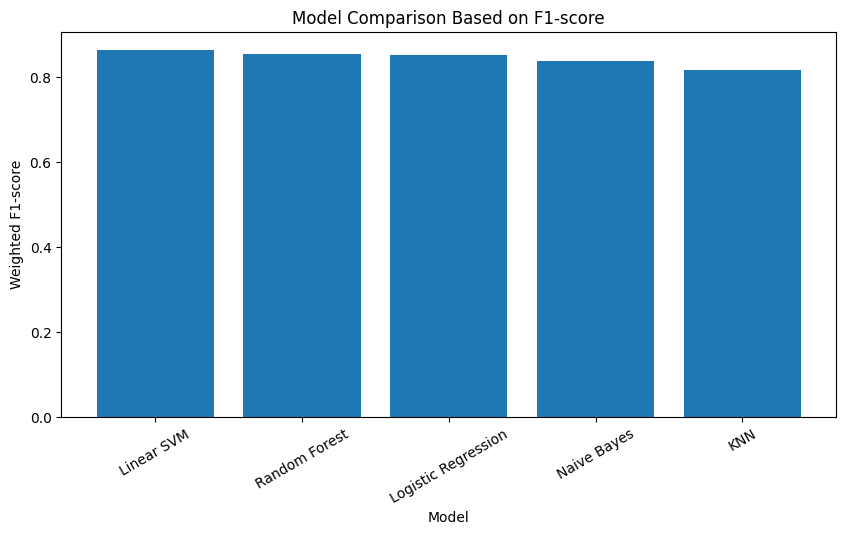

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["F1-score"])
plt.xlabel("Model")
plt.ylabel("Weighted F1-score")
plt.title("Model Comparison Based on F1-score")
plt.xticks(rotation=30)
plt.show()

In [30]:
from sklearn.metrics import classification_report

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model:", best_model_name)

best_pred = best_model.predict(X_test)

print(classification_report(y_test, best_pred))

Best model: Linear SVM
                precision    recall  f1-score   support

   ARRAY_ERROR       0.86      0.88      0.87        90
       CORRECT       0.86      0.80      0.83        90
    LOOP_ERROR       0.90      0.86      0.88        90
  METHOD_ERROR       0.82      0.90      0.86        90
VARIABLE_ERROR       0.89      0.88      0.88        90

      accuracy                           0.86       450
     macro avg       0.86      0.86      0.86       450
  weighted avg       0.86      0.86      0.86       450



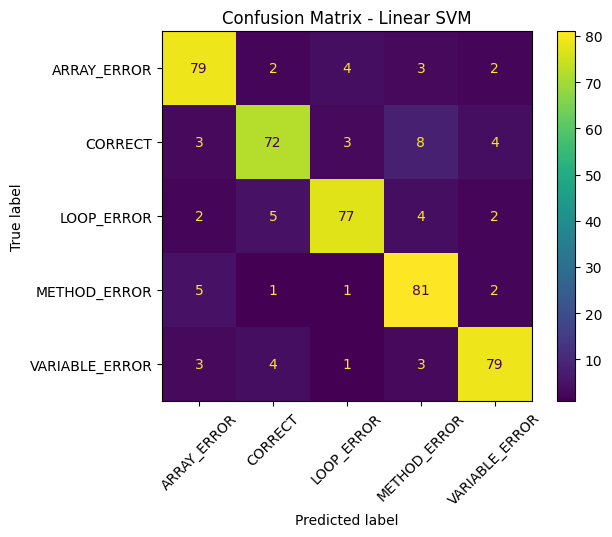

In [31]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = best_model.classes_

cm = confusion_matrix(y_test, best_pred, labels=labels)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(xticks_rotation=45)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()

In [32]:
import joblib

joblib.dump(best_model, "processed/best_error_detection_model.pkl")

print("Saved best model:", best_model_name)

Saved best model: Linear SVM


In [33]:
results_df

,Model,Accuracy,Precision,Recall,F1-score
1,Linear SVM,0.862222,0.863402,0.862222,0.862108
2,Random Forest,0.853333,0.853595,0.853333,0.852589
0,Logistic Regression,0.851111,0.853225,0.851111,0.851028
3,Naive Bayes,0.835556,0.846275,0.835556,0.837186
4,KNN,0.815556,0.820455,0.815556,0.815590


In [1]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path("D:/Work/Research_ML_Dataset")
PROCESSED_DIR = BASE_DIR / "processed"

input_path = PROCESSED_DIR / "final_dataset_with_reason_labels.csv"

df_reason = pd.read_csv(input_path)

print("Rows:", len(df_reason))
print("Columns:", df_reason.columns.tolist())

df_reason.head()

Rows: 2250
Columns: ['filename', 'source', 'label', 'concept', 'error_description', 'error_type', 'reason_label', 'code', 'clean_code']


,filename,source,label,concept,error_description,error_type,reason_label,code,clean_code
0,SYN_LOOP_01217.java,synthetic,LOOP_ERROR,Loops,Modifying for-each loop variable,CONCEPTUAL,LOOP_MISSING_UPDATE,// Intended error: Modifying loop variable doe...,public class Main { public static void main(St...
1,SYN_LOOP_01301.java,synthetic,LOOP_ERROR,Loops,Modifying for-each loop variable,CONCEPTUAL,LOOP_MISSING_UPDATE,// Intended error: Modifying loop variable doe...,public class Main { public static void main(St...
2,SYN_LOOP_00941.java,synthetic,LOOP_ERROR,Loops,Modifying for-each loop variable,CONCEPTUAL,LOOP_MISSING_UPDATE,// Intended error: Modifying loop variable doe...,public class Main { public static void main(St...
3,SYN_LOOP_00677.java,synthetic,LOOP_ERROR,Loops,Modifying for-each loop variable,CONCEPTUAL,LOOP_MISSING_UPDATE,// Intended error: Modifying loop variable doe...,public class Main { public static void main(St...
4,SYN_LOOP_01181.java,synthetic,LOOP_ERROR,Loops,Modifying for-each loop variable,CONCEPTUAL,LOOP_MISSING_UPDATE,// Intended error: Modifying loop variable doe...,public class Main { public static void main(St...


In [2]:
def get_reason_group(reason_label):
    group_map = {
        # LOOP_ERROR
        "LOOP_OFF_BY_ONE": "LOOP_BOUNDARY_ISSUE",
        "LOOP_WRONG_CONDITION": "LOOP_CONDITION_ISSUE",
        "LOOP_MISSING_UPDATE": "LOOP_UPDATE_ISSUE",
        "LOOP_CONTINUE_SKIP_UPDATE": "LOOP_CONTROL_FLOW_ISSUE",
        "LOOP_WRONG_COUNTER_DIRECTION": "LOOP_UPDATE_ISSUE",

        # VARIABLE_ERROR
        "VARIABLE_WRONG_CALCULATION": "VARIABLE_CALCULATION_ISSUE",
        "VARIABLE_INTEGER_DIVISION": "VARIABLE_CALCULATION_ISSUE",
        "VARIABLE_WRONG_INITIALIZATION": "VARIABLE_ASSIGNMENT_ISSUE",
        "VARIABLE_OVERWRITTEN_VALUE": "VARIABLE_ASSIGNMENT_ISSUE",
        "VARIABLE_WRONG_ASSIGNMENT": "VARIABLE_ASSIGNMENT_ISSUE",

        # ARRAY_ERROR
        "ARRAY_OUT_OF_BOUNDS": "ARRAY_BOUNDARY_INDEX_ISSUE",
        "ARRAY_LENGTH_AS_INDEX": "ARRAY_BOUNDARY_INDEX_ISSUE",
        "ARRAY_WRONG_TRAVERSAL": "ARRAY_TRAVERSAL_ISSUE",
        "ARRAY_SKIPPED_ELEMENT": "ARRAY_TRAVERSAL_ISSUE",
        "ARRAY_WRONG_INDEX_VARIABLE": "ARRAY_BOUNDARY_INDEX_ISSUE",

        # METHOD_ERROR
        "METHOD_ARGUMENT_MISMATCH": "METHOD_SIGNATURE_ISSUE",
        "METHOD_PARAMETER_ORDER_ERROR": "METHOD_SIGNATURE_ISSUE",
        "METHOD_MISSING_RETURN": "METHOD_RETURN_ISSUE",
        "METHOD_WRONG_RETURN_OPERATION": "METHOD_RETURN_ISSUE",
        "METHOD_IGNORED_PARAMETER": "METHOD_PARAMETER_USAGE_ISSUE",
        "METHOD_WRONG_CALL": "METHOD_SIGNATURE_ISSUE",

        # CORRECT
        "CORRECT_NO_ERROR": "CORRECT_NO_ERROR"
    }

    return group_map.get(reason_label, "UNKNOWN")


df_reason["reason_group"] = df_reason["reason_label"].apply(get_reason_group)

print("Reason group created ✅")
df_reason[["filename", "label", "reason_label", "reason_group"]].head()

Reason group created ✅


,filename,label,reason_label,reason_group
0,SYN_LOOP_01217.java,LOOP_ERROR,LOOP_MISSING_UPDATE,LOOP_UPDATE_ISSUE
1,SYN_LOOP_01301.java,LOOP_ERROR,LOOP_MISSING_UPDATE,LOOP_UPDATE_ISSUE
2,SYN_LOOP_00941.java,LOOP_ERROR,LOOP_MISSING_UPDATE,LOOP_UPDATE_ISSUE
3,SYN_LOOP_00677.java,LOOP_ERROR,LOOP_MISSING_UPDATE,LOOP_UPDATE_ISSUE
4,SYN_LOOP_01181.java,LOOP_ERROR,LOOP_MISSING_UPDATE,LOOP_UPDATE_ISSUE


In [3]:
print("Total rows:", len(df_reason))
print("Missing reason_group:", df_reason["reason_group"].isna().sum())
print("UNKNOWN reason_group:", (df_reason["reason_group"] == "UNKNOWN").sum())

print("\nBroad label counts:")
print(df_reason["label"].value_counts())

print("\nOriginal reason_label counts:")
print(df_reason["reason_label"].value_counts())

print("\nNew reason_group counts:")
print(df_reason["reason_group"].value_counts())

Total rows: 2250
Missing reason_group: 0
UNKNOWN reason_group: 0

Broad label counts:
label
LOOP_ERROR        450
VARIABLE_ERROR    450
ARRAY_ERROR       450
METHOD_ERROR      450
CORRECT           450
Name: count, dtype: int64

Original reason_label counts:
reason_label
CORRECT_NO_ERROR                 450
ARRAY_WRONG_TRAVERSAL            219
LOOP_MISSING_UPDATE              197
METHOD_IGNORED_PARAMETER         177
VARIABLE_WRONG_ASSIGNMENT        161
ARRAY_WRONG_INDEX_VARIABLE       144
LOOP_WRONG_CONDITION             142
VARIABLE_WRONG_CALCULATION       116
METHOD_WRONG_RETURN_OPERATION     97
LOOP_OFF_BY_ONE                   91
VARIABLE_WRONG_INITIALIZATION     89
METHOD_WRONG_CALL                 81
METHOD_ARGUMENT_MISMATCH          62
VARIABLE_OVERWRITTEN_VALUE        53
ARRAY_OUT_OF_BOUNDS               48
VARIABLE_INTEGER_DIVISION         31
ARRAY_SKIPPED_ELEMENT             26
METHOD_PARAMETER_ORDER_ERROR      18
LOOP_CONTINUE_SKIP_UPDATE         16
METHOD_MISSING_RETURN    

In [4]:
output_path = PROCESSED_DIR / "final_dataset_with_reason_groups.csv"
summary_path = PROCESSED_DIR / "reason_group_summary.csv"

# Put reason_group right after reason_label
cols = list(df_reason.columns)

if "reason_group" in cols:
    cols.remove("reason_group")
    insert_index = cols.index("reason_label") + 1
    cols.insert(insert_index, "reason_group")

df_reason = df_reason[cols]

df_reason.to_csv(output_path, index=False)

summary_df = df_reason["reason_group"].value_counts().reset_index()
summary_df.columns = ["reason_group", "count"]
summary_df.to_csv(summary_path, index=False)

print("Saved:", output_path)
print("Saved:", summary_path)

Saved: D:\Work\Research_ML_Dataset\processed\final_dataset_with_reason_groups.csv
Saved: D:\Work\Research_ML_Dataset\processed\reason_group_summary.csv


In [5]:
for label in df_reason["label"].unique():
    print("\n==============================")
    print("Samples for:", label)
    print("==============================")

    display(
        df_reason[df_reason["label"] == label][
            ["filename", "label", "error_description", "reason_label", "reason_group"]
        ].head(5)
    )


Samples for: LOOP_ERROR


,filename,label,error_description,reason_label,reason_group
0,SYN_LOOP_01217.java,LOOP_ERROR,Modifying for-each loop variable,LOOP_MISSING_UPDATE,LOOP_UPDATE_ISSUE
1,SYN_LOOP_01301.java,LOOP_ERROR,Modifying for-each loop variable,LOOP_MISSING_UPDATE,LOOP_UPDATE_ISSUE
2,SYN_LOOP_00941.java,LOOP_ERROR,Modifying for-each loop variable,LOOP_MISSING_UPDATE,LOOP_UPDATE_ISSUE
3,SYN_LOOP_00677.java,LOOP_ERROR,Modifying for-each loop variable,LOOP_MISSING_UPDATE,LOOP_UPDATE_ISSUE
4,SYN_LOOP_01181.java,LOOP_ERROR,Modifying for-each loop variable,LOOP_MISSING_UPDATE,LOOP_UPDATE_ISSUE



Samples for: VARIABLE_ERROR


,filename,label,error_description,reason_label,reason_group
400,SYN_VAR_01216.java,VARIABLE_ERROR,Float precision loss,VARIABLE_WRONG_CALCULATION,VARIABLE_CALCULATION_ISSUE
401,SYN_VAR_01300.java,VARIABLE_ERROR,Float precision loss,VARIABLE_WRONG_CALCULATION,VARIABLE_CALCULATION_ISSUE
402,SYN_VAR_00940.java,VARIABLE_ERROR,Float precision loss,VARIABLE_WRONG_CALCULATION,VARIABLE_CALCULATION_ISSUE
403,SYN_VAR_00676.java,VARIABLE_ERROR,Float precision loss,VARIABLE_WRONG_CALCULATION,VARIABLE_CALCULATION_ISSUE
404,SYN_VAR_01180.java,VARIABLE_ERROR,Float precision loss,VARIABLE_WRONG_CALCULATION,VARIABLE_CALCULATION_ISSUE



Samples for: ARRAY_ERROR


,filename,label,error_description,reason_label,reason_group
800,SYN_ARRAY_01217.java,ARRAY_ERROR,Comparing arrays with ==,ARRAY_WRONG_TRAVERSAL,ARRAY_TRAVERSAL_ISSUE
801,SYN_ARRAY_01301.java,ARRAY_ERROR,Comparing arrays with ==,ARRAY_WRONG_TRAVERSAL,ARRAY_TRAVERSAL_ISSUE
802,SYN_ARRAY_00941.java,ARRAY_ERROR,Comparing arrays with ==,ARRAY_WRONG_TRAVERSAL,ARRAY_TRAVERSAL_ISSUE
803,SYN_ARRAY_00677.java,ARRAY_ERROR,Comparing arrays with ==,ARRAY_WRONG_TRAVERSAL,ARRAY_TRAVERSAL_ISSUE
804,SYN_ARRAY_01181.java,ARRAY_ERROR,Comparing arrays with ==,ARRAY_WRONG_TRAVERSAL,ARRAY_TRAVERSAL_ISSUE



Samples for: METHOD_ERROR


,filename,label,error_description,reason_label,reason_group
1200,SYN_METHOD_01211.java,METHOD_ERROR,Overloading ambiguous types,METHOD_ARGUMENT_MISMATCH,METHOD_SIGNATURE_ISSUE
1201,SYN_METHOD_01643.java,METHOD_ERROR,Overloading ambiguous types,METHOD_ARGUMENT_MISMATCH,METHOD_SIGNATURE_ISSUE
1202,SYN_METHOD_00947.java,METHOD_ERROR,Overloading ambiguous types,METHOD_ARGUMENT_MISMATCH,METHOD_SIGNATURE_ISSUE
1203,SYN_METHOD_00683.java,METHOD_ERROR,Overloading ambiguous types,METHOD_ARGUMENT_MISMATCH,METHOD_SIGNATURE_ISSUE
1204,SYN_METHOD_01175.java,METHOD_ERROR,Overloading ambiguous types,METHOD_ARGUMENT_MISMATCH,METHOD_SIGNATURE_ISSUE



Samples for: CORRECT


,filename,label,error_description,reason_label,reason_group
1600,SYN_CORRECT_01861.java,CORRECT,No error,CORRECT_NO_ERROR,CORRECT_NO_ERROR
1601,SYN_CORRECT_00354.java,CORRECT,No error,CORRECT_NO_ERROR,CORRECT_NO_ERROR
1602,SYN_CORRECT_01334.java,CORRECT,No error,CORRECT_NO_ERROR,CORRECT_NO_ERROR
1603,SYN_CORRECT_00906.java,CORRECT,No error,CORRECT_NO_ERROR,CORRECT_NO_ERROR
1604,SYN_CORRECT_01290.java,CORRECT,No error,CORRECT_NO_ERROR,CORRECT_NO_ERROR


In [6]:
import pandas as pd

reason_df = pd.read_csv("D:/Work/Research_ML_Dataset/processed/final_dataset_with_reason_groups.csv")

print("Rows:", len(reason_df))
print("\nReason group counts:")
print(reason_df["reason_group"].value_counts())

reason_df.head()

Rows: 2250

Reason group counts:
reason_group
CORRECT_NO_ERROR                450
VARIABLE_ASSIGNMENT_ISSUE       303
ARRAY_TRAVERSAL_ISSUE           245
ARRAY_BOUNDARY_INDEX_ISSUE      205
LOOP_UPDATE_ISSUE               201
METHOD_PARAMETER_USAGE_ISSUE    177
METHOD_SIGNATURE_ISSUE          161
VARIABLE_CALCULATION_ISSUE      147
LOOP_CONDITION_ISSUE            142
METHOD_RETURN_ISSUE             112
LOOP_BOUNDARY_ISSUE              91
LOOP_CONTROL_FLOW_ISSUE          16
Name: count, dtype: int64


,filename,source,label,concept,error_description,error_type,reason_label,reason_group,code,clean_code
0,SYN_LOOP_01217.java,synthetic,LOOP_ERROR,Loops,Modifying for-each loop variable,CONCEPTUAL,LOOP_MISSING_UPDATE,LOOP_UPDATE_ISSUE,// Intended error: Modifying loop variable doe...,public class Main { public static void main(St...
1,SYN_LOOP_01301.java,synthetic,LOOP_ERROR,Loops,Modifying for-each loop variable,CONCEPTUAL,LOOP_MISSING_UPDATE,LOOP_UPDATE_ISSUE,// Intended error: Modifying loop variable doe...,public class Main { public static void main(St...
2,SYN_LOOP_00941.java,synthetic,LOOP_ERROR,Loops,Modifying for-each loop variable,CONCEPTUAL,LOOP_MISSING_UPDATE,LOOP_UPDATE_ISSUE,// Intended error: Modifying loop variable doe...,public class Main { public static void main(St...
3,SYN_LOOP_00677.java,synthetic,LOOP_ERROR,Loops,Modifying for-each loop variable,CONCEPTUAL,LOOP_MISSING_UPDATE,LOOP_UPDATE_ISSUE,// Intended error: Modifying loop variable doe...,public class Main { public static void main(St...
4,SYN_LOOP_01181.java,synthetic,LOOP_ERROR,Loops,Modifying for-each loop variable,CONCEPTUAL,LOOP_MISSING_UPDATE,LOOP_UPDATE_ISSUE,// Intended error: Modifying loop variable doe...,public class Main { public static void main(St...


In [7]:
from sklearn.model_selection import train_test_split

X = reason_df["clean_code"]
y = reason_df["reason_group"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTest label counts:")
print(y_test.value_counts())

Training samples: 1800
Testing samples: 450

Test label counts:
reason_group
CORRECT_NO_ERROR                90
VARIABLE_ASSIGNMENT_ISSUE       61
ARRAY_TRAVERSAL_ISSUE           49
ARRAY_BOUNDARY_INDEX_ISSUE      41
LOOP_UPDATE_ISSUE               40
METHOD_PARAMETER_USAGE_ISSUE    35
METHOD_SIGNATURE_ISSUE          32
VARIABLE_CALCULATION_ISSUE      30
LOOP_CONDITION_ISSUE            28
METHOD_RETURN_ISSUE             23
LOOP_BOUNDARY_ISSUE             18
LOOP_CONTROL_FLOW_ISSUE          3
Name: count, dtype: int64


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score, precision_recall_fscore_support

models = {
    "Logistic Regression": LogisticRegression(max_iter=3000, random_state=42),
    "Linear SVM": LinearSVC(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Naive Bayes": MultinomialNB(),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

reason_results = []
trained_reason_models = {}

for name, clf in models.items():
    print(f"Training {name}...")
    
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=7000,
            ngram_range=(1, 2)
        )),
        ("classifier", clf)
    ])
    
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    
    accuracy = accuracy_score(y_test, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )
    
    reason_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })
    
    trained_reason_models[name] = pipeline

reason_results_df = pd.DataFrame(reason_results)
reason_results_df = reason_results_df.sort_values(by="F1-score", ascending=False)

reason_results_df

Training Logistic Regression...
Training Linear SVM...
Training Random Forest...
Training Naive Bayes...
Training KNN...


,Model,Accuracy,Precision,Recall,F1-score
1,Linear SVM,0.802222,0.804238,0.802222,0.802170
2,Random Forest,0.777778,0.789620,0.777778,0.780053
0,Logistic Regression,0.760000,0.746022,0.760000,0.747132
4,KNN,0.624444,0.637118,0.624444,0.613993
3,Naive Bayes,0.466667,0.516552,0.466667,0.401735


In [9]:
from sklearn.metrics import classification_report

best_reason_model_name = reason_results_df.iloc[0]["Model"]
best_reason_model = trained_reason_models[best_reason_model_name]

reason_pred = best_reason_model.predict(X_test)

print("Best reason-group model:", best_reason_model_name)
print("\nClassification Report:")
print(classification_report(y_test, reason_pred, zero_division=0))

Best reason-group model: Linear SVM

Classification Report:
                              precision    recall  f1-score   support

  ARRAY_BOUNDARY_INDEX_ISSUE       0.82      0.80      0.81        41
       ARRAY_TRAVERSAL_ISSUE       0.80      0.73      0.77        49
            CORRECT_NO_ERROR       0.76      0.79      0.77        90
         LOOP_BOUNDARY_ISSUE       0.28      0.28      0.28        18
        LOOP_CONDITION_ISSUE       0.69      0.79      0.73        28
     LOOP_CONTROL_FLOW_ISSUE       1.00      1.00      1.00         3
           LOOP_UPDATE_ISSUE       0.78      0.70      0.74        40
METHOD_PARAMETER_USAGE_ISSUE       1.00      1.00      1.00        35
         METHOD_RETURN_ISSUE       0.71      0.74      0.72        23
      METHOD_SIGNATURE_ISSUE       0.93      0.88      0.90        32
   VARIABLE_ASSIGNMENT_ISSUE       0.88      0.95      0.91        61
  VARIABLE_CALCULATION_ISSUE       0.93      0.83      0.88        30

                    accuracy

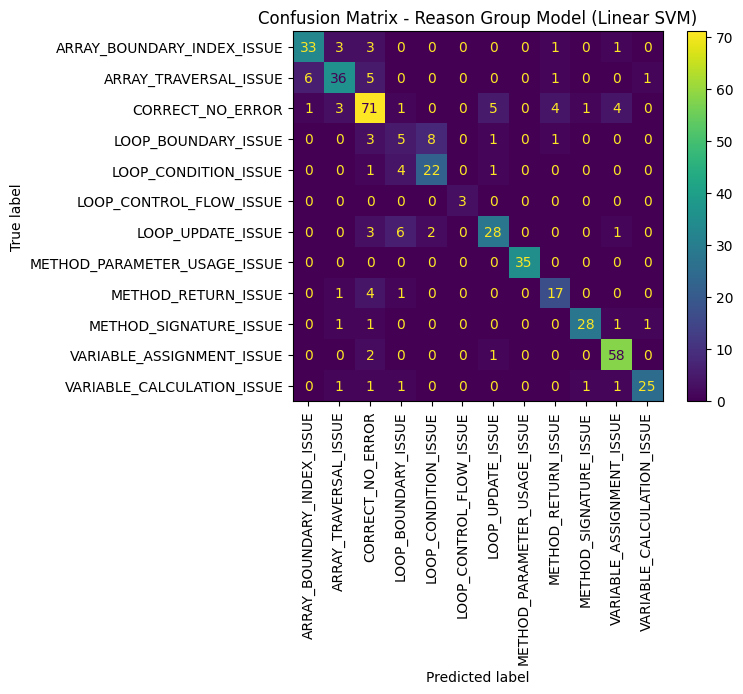

In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = best_reason_model.classes_

cm = confusion_matrix(y_test, reason_pred, labels=labels)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(xticks_rotation=90)

plt.title(f"Confusion Matrix - Reason Group Model ({best_reason_model_name})")
plt.show()

In [11]:
import joblib

model_output_path = "D:/Work/Research_ML_Dataset/processed/best_reason_detection_model.pkl"
results_output_path = "D:/Work/Research_ML_Dataset/processed/reason_model_results.csv"

joblib.dump(best_reason_model, model_output_path)
reason_results_df.to_csv(results_output_path, index=False)

print("Saved reason model:", model_output_path)
print("Saved reason model results:", results_output_path)
print("Best reason model:", best_reason_model_name)

Saved reason model: D:/Work/Research_ML_Dataset/processed/best_reason_detection_model.pkl
Saved reason model results: D:/Work/Research_ML_Dataset/processed/reason_model_results.csv
Best reason model: Linear SVM
